# 作业3：NumPy、Matplotlib 与 pandas

姓名：张梓望　　学号：20244081104　　班级：24 数信 01 班

In [1]:
import hashlib
import os
import platform
import uuid
# 修改为自己的学号
STUDENT_ID = 20244081104
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] pytorch
[学号]       20244081104
[机器指纹] 90bdc247d63f884e
[RUN_ID]   20244081104-90bdc247d63f884e


In [2]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

## 围绕半圆定律

Wigner 矩阵的构造方式是：`1 \le i \le j \le n` 的 `Z_{ij}` 独立取自 `N(0, 1/n)`，
再令 `Z_{ji} = Z_{ij}`。半圆密度为

$$f(x)=\frac{1}{2\pi}\sqrt{4-x^2},\qquad |x|\le 2,$$

`|x| > 2` 时为 0。

In [3]:
def wigner_density(x):
    x = float(x)
    if abs(x) > 2:
        return 0.0
    return float(np.sqrt(4 - x * x) / (2 * np.pi))


for t in (-2.0, -1.0, 0.0, 1.0, 2.0, 3.0):
    print(f"f({t:>4}) = {wigner_density(t):.6f}")

f(-2.0) = 0.000000
f(-1.0) = 0.275664
f( 0.0) = 0.318310
f( 1.0) = 0.275664
f( 2.0) = 0.000000
f( 3.0) = 0.000000


In [4]:
def generate_wigner(n):
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError(f"n 必须是整数，收到 {type(n).__name__}")
    if n <= 0:
        raise ValueError(f"n 必须是正整数，收到 {n}")

    n = int(n)
    z = np.random.normal(0.0, np.sqrt(1.0 / n), size=(n, n))
    return np.triu(z) + np.triu(z, 1).T


m = generate_wigner(4)
print("4x4 Wigner 矩阵：")
print(np.round(m, 4))
print("是否对称：", np.allclose(m, m.T))

4x4 Wigner 矩阵：
[[ 0.7832 -0.2791  0.0811  0.4695]
 [-0.2791  0.3045 -0.3909  0.6377]
 [ 0.0811 -0.3909 -0.1283 -0.0166]
 [ 0.4695  0.6377 -0.0166  1.0327]]
是否对称： True


In [5]:
for bad in (0, -3, 2.5, "10", True):
    try:
        generate_wigner(bad)
    except (TypeError, ValueError) as e:
        print(type(e).__name__, bad, e)

ValueError 0 n 必须是正整数，收到 0
ValueError -3 n 必须是正整数，收到 -3
TypeError 2.5 n 必须是整数，收到 float
TypeError 10 n 必须是整数，收到 str
TypeError True n 必须是整数，收到 bool


In [6]:
def get_spectrum(matrix):
    return np.sort(np.linalg.eigvalsh(np.asarray(matrix)))


eig = get_spectrum(generate_wigner(5))
print("特征值：", np.round(eig, 6))
print("是否非递减：", bool(np.all(np.diff(eig) >= -1e-12)))

特征值： [-1.056302 -0.724523 -0.119463  0.15272   0.869971]
是否非递减： True


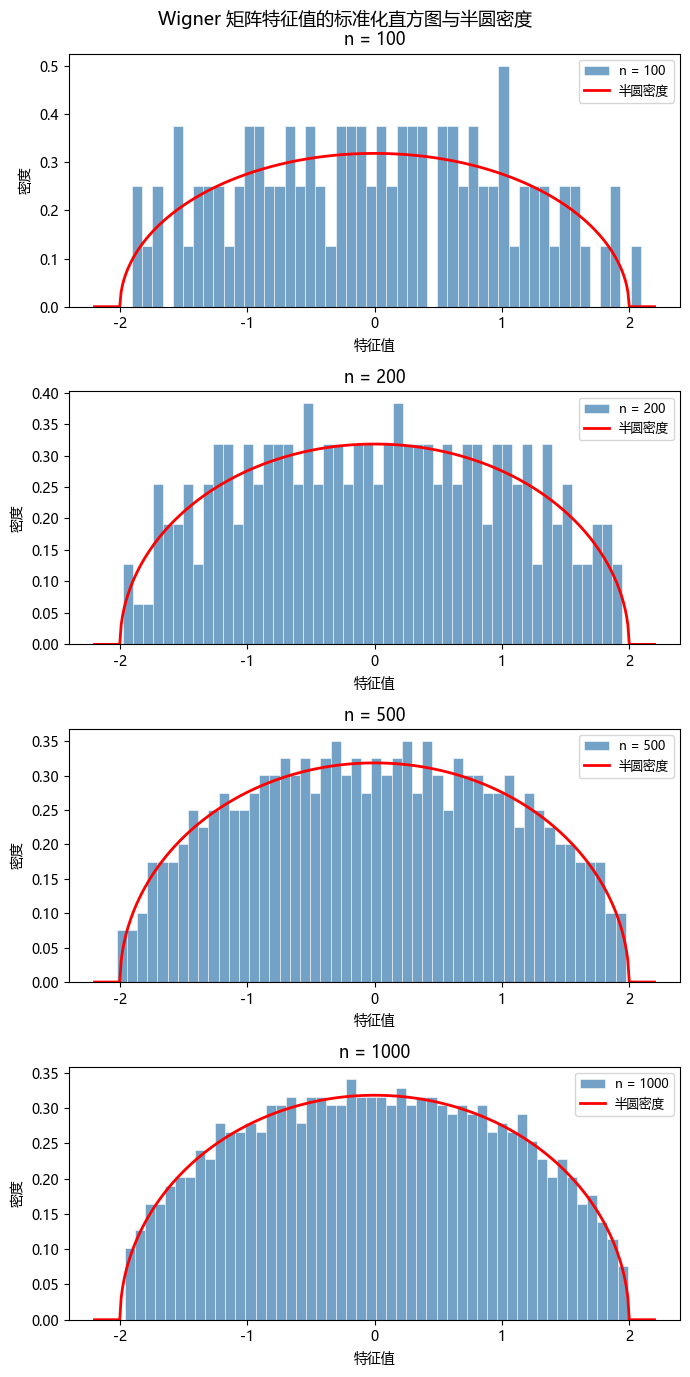

In [7]:
np.random.seed(2024)

sizes = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(7, 14))

xs = np.linspace(-2.2, 2.2, 400)
curve = np.array([wigner_density(v) for v in xs])

for ax, n in zip(axes, sizes):
    spec = get_spectrum(generate_wigner(n))
    ax.hist(spec, bins=50, density=True, color="steelblue", alpha=0.75,
            edgecolor="white", linewidth=0.5, label=f"n = {n}")
    ax.plot(xs, curve, color="red", linewidth=2, label="半圆密度")
    ax.set_title(f"n = {n}")
    ax.set_xlabel("特征值")
    ax.set_ylabel("密度")
    ax.set_xlim(-2.4, 2.4)
    ax.legend(loc="upper right", fontsize=9)

fig.suptitle("Wigner 矩阵特征值的标准化直方图与半圆密度", fontsize=13)
plt.tight_layout()
plt.show()

n = 100 时直方图和红线还有明显出入，边缘起伏大，中间的锯齿也多。n = 200 开始成形，n = 500 的轮廓已经贴合，
n = 1000 时几乎重合。按图看，n 在 500 左右时半圆密度就能比较好地描述特征值的分布。

下面用 KS 检验看一下偏差的量级。半圆分布的累积分布函数是

$$F(x)=\frac{1}{2}+\frac{x\sqrt{4-x^2}}{4\pi}+\frac{1}{\pi}\arcsin\frac{x}{2}.$$

In [8]:
from scipy import stats


def semicircle_cdf(x):
    x = np.clip(np.asarray(x, dtype=float), -2.0, 2.0)
    return 0.5 + x * np.sqrt(np.maximum(4 - x * x, 0)) / (4 * np.pi) + np.arcsin(x / 2) / np.pi


np.random.seed(7)
for n in sizes:
    spec = get_spectrum(generate_wigner(n))
    d, p = stats.kstest(spec, semicircle_cdf)
    print(n, round(d, 4), round(1.36 / np.sqrt(n), 4))

100 0.0246 0.136
200 0.0142 0.0962
500 0.0055 0.0608


1000 0.0039 0.043


D 随 n 增大而减小，且都明显小于 5% 显著性水平下的临界值 1.36/sqrt(n)，和直方图的判断一致。
不过同一矩阵的特征值之间并不独立，KS 检验的临界值是在独立样本前提下给出的，这里的 D 更适合当作偏差大小的度量。

## Conway 的生命游戏

棋盘是 `m \times n` 的二维数组，活细胞为 1。四个方向加四个对角共八个邻居，边界环绕。
一步更新时所有细胞同时变化，所以邻居数要基于原棋盘计算。

In [9]:
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2 or board.size == 0:
        return False
    return bool(np.all((board == 0) | (board == 1)))


cases = [
    (np.array([[0, 1], [1, 0]]), "2x2 正常棋盘"),
    (np.array([[0, 2]]), "含取值 2"),
    (np.array([0, 1]), "一维数组"),
    (np.array([[0.0, 1.0], [1.0, 0.0]]), "浮点型但取值合法"),
    ("0101", "字符串"),
]
for b, desc in cases:
    print(f"{desc:<18} {is_valid_board(b)}")

2x2 正常棋盘           True
含取值 2              False
一维数组               False
浮点型但取值合法           True
字符串                False


In [10]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("输入不是合法的生命游戏棋盘")

    b = board.astype(np.int64)
    neighbors = sum(
        np.roll(np.roll(b, dy, axis=0), dx, axis=1)
        for dy in (-1, 0, 1)
        for dx in (-1, 0, 1)
        if not (dy == 0 and dx == 0)
    )

    alive = b == 1
    nxt = ((b == 0) & (neighbors == 3)) | (alive & ((neighbors == 2) | (neighbors == 3)))
    return nxt.astype(board.dtype)

In [11]:
corner = np.zeros((3, 3), dtype=int)
corner[0, 0] = 1
print("角落单细胞的下一状态：")
print(gol_step(corner))
print()
try:
    gol_step(np.array([[0, 1], [1, 3]]))
except ValueError as e:
    print("非法棋盘：", e)

角落单细胞的下一状态：
[[0 0 0]
 [0 0 0]
 [0 0 0]]

非法棋盘： 输入不是合法的生命游戏棋盘


初始活细胞数： 5


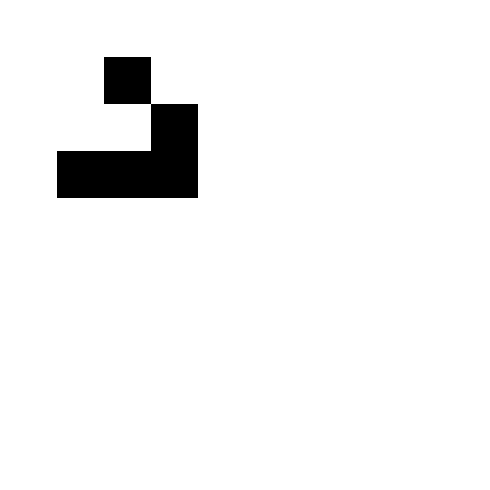

演化 4 代后活细胞数： 5


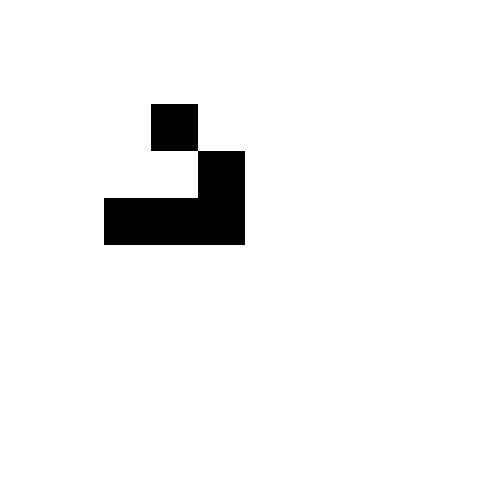

In [12]:
def draw_gol_board(board):
    plt.figure(figsize=(5, 5))
    plt.imshow(board, cmap=plt.get_cmap("gray_r"), interpolation="nearest", vmin=0, vmax=1)
    plt.xticks([])
    plt.yticks([])
    for spine in plt.gca().spines.values():
        spine.set_visible(False)
    plt.tight_layout()
    plt.show()


glider = np.zeros((10, 10), dtype=int)
glider[1, 2] = 1
glider[2, 3] = 1
glider[3, 1] = 1
glider[3, 2] = 1
glider[3, 3] = 1

print("初始活细胞数：", int(glider.sum()))
draw_gol_board(glider)
for _ in range(4):
    glider = gol_step(glider)
print("演化 4 代后活细胞数：", int(glider.sum()))
draw_gol_board(glider)

In [13]:
block = np.zeros((6, 6), dtype=int)
block[2:4, 2:4] = 1
print("2x2 方块是否静止：", np.array_equal(gol_step(block), block))

blinker = np.zeros((5, 5), dtype=int)
blinker[2, 1:4] = 1
print("1x3 闪光灯周期是否 2：", np.array_equal(gol_step(gol_step(blinker)), blinker))

2x2 方块是否静止： True
1x3 闪光灯周期是否 2： True


滑翔机演化四代后整体向右下平移一格，活细胞数保持 5 个。2x2 的方块不变化，1x3 的闪光灯周期为 2。

## 使用 pandas DataFrame

In [14]:
iris = pd.read_csv("Iris.csv")
print("形状：", iris.shape)
print("列名：", list(iris.columns))
print(iris.dtypes)
print(iris["Species"].value_counts())

形状： (150, 6)
列名： ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species              str
dtype: object
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


数据集共 150 个数据点，6 列：Id 是编号，四列以 Cm 结尾的是测量值，Species 是品种名。Id 为整数，四个测量列为 float64，Species 为文本。三个品种各 50 条。

第 35 行（索引 34）的第四项测量有误，第 38 行（索引 37）的第二、三项有误，按题目给的数值改写整行，Id 保持不变。

In [15]:
print("修改前：")
print(iris.loc[[34, 37]])

iris.loc[34] = [35, 4.9, 3.1, 1.5, 0.2, "Iris-setosa"]
iris.loc[37] = [38, 4.9, 3.6, 1.4, 0.1, "Iris-setosa"]

print()
print("修改后：")
print(iris.loc[[34, 37]])

修改前：
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34  35            4.9           3.1            1.5           0.1  Iris-setosa
37  38            4.9           3.1            1.5           0.1  Iris-setosa

修改后：
    Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
34  35            4.9           3.1            1.5           0.2  Iris-setosa
37  38            4.9           3.6            1.4           0.1  Iris-setosa


In [16]:
iris["Petal.Ratio"] = iris["PetalLengthCm"] / iris["PetalWidthCm"]
iris["Sepal.Ratio"] = iris["SepalLengthCm"] / iris["SepalWidthCm"]

print(iris.head())
print(iris[["Petal.Ratio", "Sepal.Ratio"]].describe())

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species  \
0   1            5.1           3.5            1.4           0.2  Iris-setosa   
1   2            4.9           3.0            1.4           0.2  Iris-setosa   
2   3            4.7           3.2            1.3           0.2  Iris-setosa   
3   4            4.6           3.1            1.5           0.2  Iris-setosa   
4   5            5.0           3.6            1.4           0.2  Iris-setosa   

   Petal.Ratio  Sepal.Ratio  
0          7.0     1.457143  
1          7.0     1.633333  
2          6.5     1.468750  
3          7.5     1.483871  
4          7.0     1.388889  
       Petal.Ratio  Sepal.Ratio
count   150.000000   150.000000
mean      4.310500     1.953681
std       2.489648     0.400480
min       2.125000     1.268293
25%       2.802381     1.546188
50%       3.300000     2.032292
75%       4.666667     2.224910
max      15.000000     2.961538


In [17]:
iris.to_csv("iris_corrected.csv", index=False)

check = pd.read_csv("iris_corrected.csv")
print("读回形状：", check.shape)
print("列名一致：", list(check.columns) == list(iris.columns))
print("数值一致：", np.allclose(check.select_dtypes("number").to_numpy(),
                              iris.select_dtypes("number").to_numpy()))

读回形状： (150, 8)
列名一致： True
数值一致： True


In [18]:
summary = iris.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(summary)

                Petal.Ratio                              Sepal.Ratio         \
                       mean median    min     max    std        mean median   
Species                                                                       
Iris-setosa          6.9080 7.0000 2.6667 15.0000 2.8545      1.4702 1.4631   
Iris-versicolor      3.2428 3.2404 2.6667  4.1000 0.3125      2.1604 2.1613   
Iris-virginica       2.7807 2.6667 2.1250  4.0000 0.4074      2.2305 2.1695   

                                      
                   min    max    std  
Species                               
Iris-setosa     1.2683 1.9565 0.1187  
Iris-versicolor 1.7647 2.8182 0.2287  
Iris-virginica  1.8235 2.9615 0.2470  


Iris-setosa 的花瓣比值明显偏高，因为它花瓣宽度很小。Iris-versicolor 和 Iris-virginica 的花瓣比值都在 3 到 4 之间，
萼片比值三者相差不大。